# gNATSGO Available Water Storage (`aws0_150`) Raster Prep

Queries, streams, clips, and aligns Microsoft Planetary Computer's `gnatsgo-rasters` (`aws0_150`) Cloud Optimized GeoTIFFs to the exact six-state `EPSG:5070` grid used in `cont_SHC_raster_prep.py` and `NLCD_raster_prep2.py`.

- **Source**: [Planetary Computer `gnatsgo-rasters`](https://planetarycomputer.microsoft.com/dataset/gnatsgo-rasters)
- **Asset**: `aws0_150` — Available water storage estimate (0–150 cm depth), expressed in `mm`

In [2]:
import os
import subprocess
import geopandas as gpd
import osmnx as ox
import planetary_computer
import pystac_client
import rasterio
from rasterio.enums import Resampling
from shapely.geometry import mapping
import matplotlib.pyplot as plt

states = [
    "Ohio",
    "Michigan",
    "Indiana",
    "Pennsylvania",
    "Kentucky",
    "West Virginia",
]

ASSET_KEY = "aws0_150"  # Available water storage 0-150 cm (mm)
DST_CRS = "EPSG:5070"
DST_NODATA = -9999.0  # Float32 nodata for continuous AWS

WORK_DIR = "/kaggle/working"
os.makedirs(WORK_DIR, exist_ok=True)

In [3]:
# 1. Build 6-state bounding polygon and lock exact 30m-aligned EPSG:5070 bounds
ox.settings.cache_folder = os.path.join(WORK_DIR, "cache")

region_queries = [f"{state}, USA" for state in states]
regions_gdf = ox.geocode_to_gdf(region_queries)

# Keep WGS84 boundary for STAC spatial intersection
boundary_4326 = regions_gdf.to_crs("EPSG:4326").union_all().buffer(0)

# Project to EPSG:5070 BEFORE unioning/buffering so geometry ops happen in meters
regions_5070 = regions_gdf.to_crs(DST_CRS)
master_boundary = regions_5070.union_all().buffer(0)

cutline_path = os.path.join(WORK_DIR, "six_state_cutline_5070.gpkg")
gpd.GeoDataFrame(geometry=[master_boundary], crs=DST_CRS).to_file(
    cutline_path, driver="GPKG"
)

# Exact same 30m-aligned bounding box logic as cont_SHC_raster_prep.py
minx, miny, maxx, maxy = master_boundary.bounds
te_bounds = [
    str(int(minx // 30) * 30),
    str(int(miny // 30) * 30),
    str(int((maxx // 30) + 1) * 30),
    str(int((maxy // 30) + 1) * 30),
]
print(f"Locked 30m aligned bounds (EPSG:5070): {te_bounds}")

Locked 30m aligned bounds (EPSG:5070): ['429030', '1513980', '1781880', '2834850']


In [4]:
# 2. Query Planetary Computer STAC API for intersecting gNATSGO COG tiles
# NOTE: assets are deliberately left unsigned here. PC SAS tokens expire in
# ~45 min, so signing happens right before each read in the next cell.
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
)

search = catalog.search(
    collections=["gnatsgo-rasters"],
    intersects=mapping(boundary_4326),
)
items = list(search.item_collection())
if not items:
    raise RuntimeError("No gNATSGO items found for the 6-state boundary.")

print(f"Total intersecting gNATSGO tiles: {len(items)}")


Total intersecting gNATSGO tiles: 51


In [5]:
# 3. Mosaic in batches (re-signing each batch), warp each batch to a local
#    30m EPSG:5070 intermediate, then do a single final clip/align pass.
import shutil

BATCH_SIZE = 8            # tiles per signed batch (~each batch < one token TTL)
KEEP_INTERMEDIATES = False

vrt_path = os.path.join(WORK_DIR, f"gnatsgo_{ASSET_KEY}.vrt")
out_path = os.path.join(WORK_DIR, f"gnatsgo_{ASSET_KEY}_clipped_reproj.tiff")
inter_dir = os.path.join(WORK_DIR, f"gnatsgo_{ASSET_KEY}_batches")
os.makedirs(inter_dir, exist_ok=True)

GDAL_CFG = [
    "--config", "GDAL_DISABLE_READDIR_ON_OPEN", "EMPTY_DIR",
    "--config", "GDAL_HTTP_MERGE_CONSECUTIVE_RANGES", "YES",
    "--config", "VSI_CACHE", "TRUE",
    "--config", "GDAL_HTTP_MAX_RETRY", "5",
    "--config", "GDAL_HTTP_RETRY_DELAY", "3",
]

CO_OPTS = [
    "-co", "COMPRESS=LZW", "-co", "TILED=YES",
    "-co", "BLOCKXSIZE=512", "-co", "BLOCKYSIZE=512",
    "-co", "BIGTIFF=YES",
]


def run(cmd):
    try:
        subprocess.run(cmd, check=True, capture_output=True, text=True)
    except subprocess.CalledProcessError as e:
        print("\nGDAL ERROR:")
        print(e.stderr[-4000:])
        raise


def signed_vsi(subset):
    """Sign right before reading: a cached SAS token is refreshed once it is
    within a minute of expiry, but never sign into a long-lived artifact."""
    return [f"/vsicurl/{planetary_computer.sign(i.assets[ASSET_KEY].href)}" for i in subset]


intermediates = []
for start in range(0, len(items), BATCH_SIZE):
    batch = items[start : start + BATCH_SIZE]
    name = f"batch_{start:03d}"
    batch_vrt = os.path.join(inter_dir, f"{name}.vrt")
    inter_path = os.path.join(inter_dir, f"{name}.tiff")
    tmp_path = inter_path + ".tmp"

    if os.path.exists(inter_path) and os.path.getsize(inter_path) > 0:
        print(f"[{name}] already complete, skipping")
        intermediates.append(inter_path)
        continue

    print(f"[{name}] {len(batch)} tiles ...", end="", flush=True)
    run(["gdalbuildvrt", "-overwrite", batch_vrt, *signed_vsi(batch)])
    run([
        "gdalwarp",
        "-overwrite",
        "-of", "GTiff",                # explicit: ".tiff.tmp" has no inferable driver
        "-t_srs", DST_CRS,
        "-tr", "30", "30",
        "-tap",                        # lock to the same 30m lattice as the final grid
        "-r", "average",
        "-dstnodata", str(DST_NODATA),
        "-ot", "Float32",
        "-multi",
        "-wo", "NUM_THREADS=ALL_CPUS",
        *GDAL_CFG,
        *CO_OPTS,
        batch_vrt,
        tmp_path,
    ])
    os.replace(tmp_path, inter_path)   # only complete intermediates are kept
    os.remove(batch_vrt)
    print(f" {os.path.getsize(inter_path) / 1e9:.2f} GB")
    intermediates.append(inter_path)

# Final pass: local-only reads, exact shared grid with NLCD/POLARIS rasters
run(["gdalbuildvrt", "-overwrite", vrt_path, *intermediates])
run([
    "gdalwarp",
    "-overwrite",
    "-of", "GTiff",
    "-t_srs", DST_CRS,
    "-te", *te_bounds,             # Exact shared extent with NLCD/POLARIS rasters
    "-tr", "30", "30",             # Exact 30m x 30m resolution
    "-r", "near",                  # 1:1 with the intermediates: no resampling
    "-cutline", cutline_path,
    "-dstnodata", str(DST_NODATA),
    "-ot", "Float32",
    "-multi",
    "-wo", "NUM_THREADS=ALL_CPUS",
    *GDAL_CFG,
    *CO_OPTS,
    vrt_path,
    out_path,
])
print(f"Successfully wrote {out_path}")

# Clean up temporary cutline GeoPackage and VRTs
for tmp in (cutline_path, vrt_path):
    if os.path.exists(tmp):
        os.remove(tmp)
if not KEEP_INTERMEDIATES:
    shutil.rmtree(inter_dir, ignore_errors=True)


[batch_000] 8 tiles ... 0.62 GB
[batch_008] 8 tiles ... 0.68 GB
[batch_016] 8 tiles ... 0.51 GB
[batch_024] 8 tiles ... 0.59 GB
[batch_032] 8 tiles ... 0.71 GB
[batch_040] 8 tiles ... 0.57 GB
[batch_048] 3 tiles ... 0.29 GB
Successfully wrote /kaggle/working/gnatsgo_aws0_150_clipped_reproj.tiff


gNATSGO aws0_150 | shape: (44029, 45095) | CRS: EPSG:5070 | dtype: float32 | nodata: -9999.0
  -> Grid check passed: exact match with /kaggle/input/datasets/maanav0114/ambystoma-sdm-data/land_cover_clipped_reproj.tiff


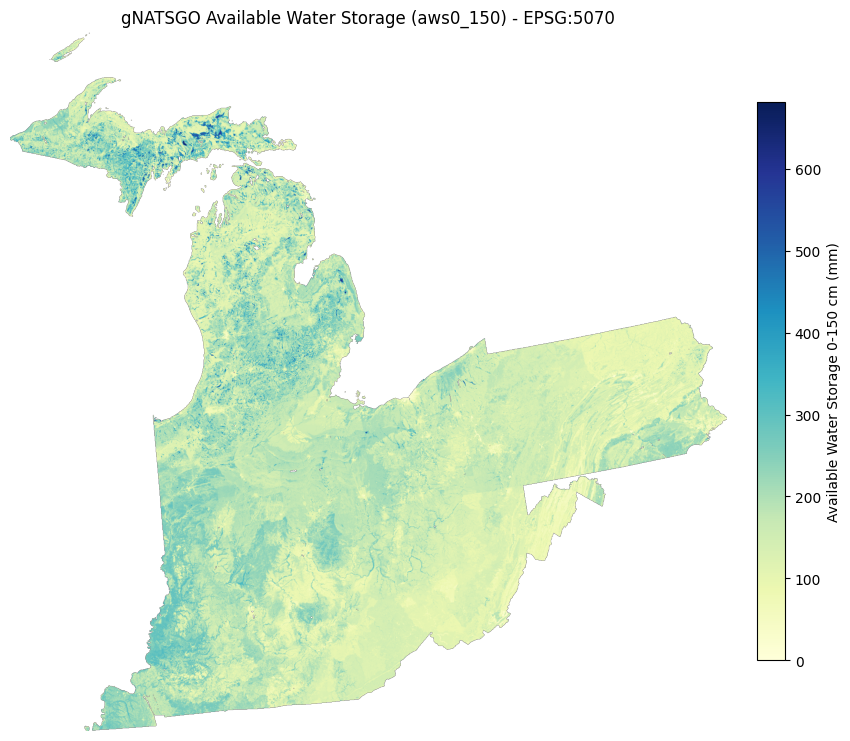

In [6]:
# 4. Verify grid alignment against NLCD reference and plot downsampled preview
ref_nlcd = "/kaggle/input/datasets/maanav0114/ambystoma-sdm-data/land_cover_clipped_reproj.tiff"

with rasterio.open(out_path) as src:
    print(
        f"gNATSGO {ASSET_KEY} | shape: {src.shape} | CRS: {src.crs} | "
        f"dtype: {src.dtypes[0]} | nodata: {src.nodata}"
    )
    if os.path.exists(ref_nlcd):
        with rasterio.open(ref_nlcd) as ref:
            assert src.shape == ref.shape, f"Shape mismatch: {src.shape} vs {ref.shape}"
            assert src.crs == ref.crs, f"CRS mismatch: {src.crs} vs {ref.crs}"
            assert src.transform == ref.transform, "Affine transform mismatch!"
            print(f"  -> Grid check passed: exact match with {ref_nlcd}")

    max_size = 1500
    scale = min(max_size / src.width, max_size / src.height)
    width = max(1, int(src.width * scale))
    height = max(1, int(src.height * scale))

    image = src.read(
        1,
        out_shape=(height, width),
        resampling=Resampling.average,
        masked=True,
    )

fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(image, cmap="YlGnBu")
plt.colorbar(im, ax=ax, fraction=0.036, pad=0.04, label="Available Water Storage 0-150 cm (mm)")
ax.set_title("gNATSGO Available Water Storage (aws0_150) - EPSG:5070")
ax.axis("off")
plt.show()